# Feature Engineerung und Metriken
In diesem Notebook überführen wir die Rohdaten in die 5 Composite Scores (Perk-Indizes), mit denen wir im Anschluss das Fuzzy Ranking durchführen.

# Zelle 1: Daten laden

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Bereinigte Daten aus der EDA laden
df = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

print(f"Datensatz mit {len(df):,} Usern für Feature Engineering geladen.")

Datensatz mit 50,000 Usern für Feature Engineering geladen.


# Zelle 2: Composite Signals & Perzentil-Ranking berechnen

*Um alle Kunden fair zu vergleichen, berechnen wir für jeden Perk eine gewichtete Kombination aus Verhaltensmerkmalen und wenden darauf das Perzentil-Ranking (rank(pct=True)) an:*

1. **meal_index** ( Free hotel meal):
> Signal = avg_room_price_per_night_usd * total_hotel_nights
2. **baggage_index** ( Free checked bag):
> Signal = avg_checked_bags_per_flight * (1+has_children) * total_seats_booked
3. **cancellation_index** ( No cancellation fees):
> Signal = cancellation_rate_pct + total_cancellations
4. **bargain_hunter_index** ( Exclusive discounts):
> Signal = avg_flight_discount_pct * flight_discount_sessions + avg_page_clicks
5. **free_night_index** ( 1 night free hotel with flight):
> Signal = combined_flight_and_hotel_trips * total_hotel_nights


Der Parameter pct=True in der Pandas DataFrame rank() Methode skaliert die berechneten Ränge als Prozentränge (Percentiles) auf einen Wert zwischen 0.0 und 1.0.

In [ ]:
# 1. Unskalierte Verhaltens-Signale erzeugen
df_features = pd.DataFrame({'user_id': df['user_id']})

# Signal 1: Free hotel meal
df_features['raw_meal'] = df['avg_room_price_per_night_usd'] * (df['total_hotel_nights'] + 1)

# Signal 2: Free checked bag
df_features['raw_baggage'] = df['avg_checked_bags_per_flight'] * (1 + df['has_children']) * (df['total_seats_booked'] + 1)

# Signal 3: No cancellation fees
df_features['raw_cancellation'] = df['cancellation_rate_pct'] + df['total_cancellations']

# Signal 4: Exclusive discounts (Bargain Hunter)
df_features['raw_bargain'] = (df['avg_flight_discount_pct'] * df['flight_discount_sessions']) + (df['avg_page_clicks'] / 100.0)

# Signal 5: 1 night free hotel with flight
df_features['raw_free_night'] = df['combined_flight_and_hotel_trips'] * df['total_hotel_nights']

# 2. Perzentil-Ranking anwenden (alle Werte exakt zwischen 0.0 und 1.0)
index_cols = ['meal_index', 'baggage_index', 'cancellation_index', 'bargain_hunter_index', 'free_night_index']
raw_cols = ['raw_meal', 'raw_baggage', 'raw_cancellation', 'raw_bargain', 'raw_free_night']

for raw, idx in zip(raw_cols, index_cols):
    df_features[idx] = df_features[raw].rank(pct=True)

# Überblick über die erstelleten Indizes
df_features[index_cols].describe().round(3)

,meal_index,baggage_index,cancellation_index,bargain_hunter_index,free_night_index
count,50000.000,50000.000,50000.000,50000.000,50000.000
mean,0.500,0.500,0.500,0.500,0.500
std,0.289,0.281,0.147,0.289,0.287
min,0.047,0.187,0.453,0.000,0.105
25%,0.250,0.187,0.453,0.251,0.252
50%,0.500,0.541,0.453,0.499,0.518
75%,0.750,0.751,0.453,0.750,0.748
max,1.000,1.000,1.000,1.000,1.000


# Zelle 3: Verteilung der 5 Indizes visualisieren

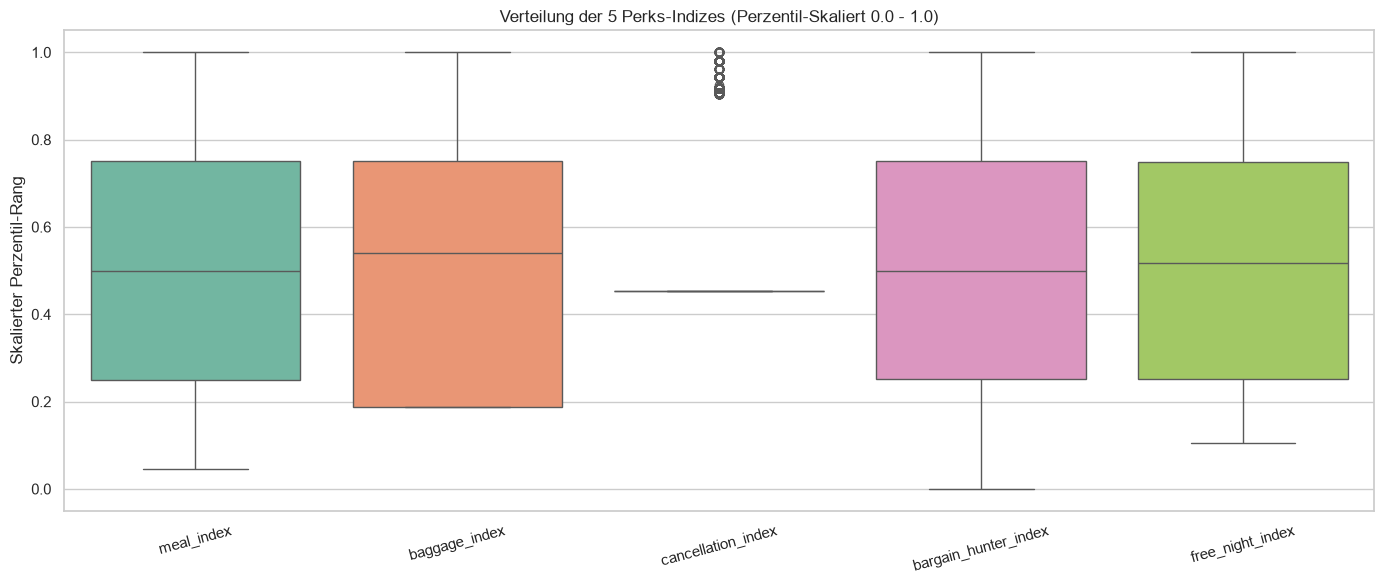

In [6]:
# Visualisierung der 5 Composite-Indizes
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_features[index_cols], palette="Set2")
plt.title("Verteilung der 5 Perks-Indizes (Perzentil-Skaliert 0.0 - 1.0)")
plt.ylabel("Skalierter Perzentil-Rang")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Zelle 4 Features / User-Pers-INdices speichern
* Die Indices sind normiert und für die weitere Auswertung normiert.
* Sie können für die spätere Zuordnung der einzelnen Kunden auf die Personas/Zielgruppen verwendet werden 

In [9]:
df_features.shape# 1. Nur die User-ID und die 5 skalierten Indizes für das Fuzzy-Modell speichern
df_export = df_features[['user_id'] + index_cols]
df_export.to_csv('data/traveltide_user_perk_indices.csv', index=False)

print("Perk-Indizes erfolgreich unter 'data/traveltide_user_perk_indices.csv' gespeichert!")

Perk-Indizes erfolgreich unter 'data/traveltide_user_perk_indices.csv' gespeichert!
